#**Step1: IMPORTING ALL THE PYTHON LIBRARY FOR THIS PROJECT**

In [ ]:
import os

# 1. Fix the filename and move it
# The * catches "kaggle .json" or "kaggle.json"
!mkdir -p ~/.kaggle
!mv /content/kaggle*.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

# 2. Re-run the download (This should work now that the key is fixed)
!kaggle datasets download -d iarunava/cell-images-for-detecting-malaria

# 3. Create the folder and unzip
!mkdir -p /content/malaria_dataset
!unzip -q cell-images-for-detecting-malaria.zip -d /content/malaria_dataset/

# 4. Final Check
if os.path.exists('/content/malaria_dataset/cell_images/Parasitized'):
    print("Success! Everything is in the right place.")
else:
    print("Still not seeing it. Refresh your sidebar and tell me what files are listed.")

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
100% 675M/675M [00:03<00:00, 210MB/s]

Success! Everything is in the right place.


In [ ]:
#Importing all the required files
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
from PIL import Image # Using PIL to open images
#ignore warnings
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve
)
from tensorflow.keras.models import load_model
import io

import ipywidgets as widgets
from IPython.display import display, clear_output

# Step 2: Configuring the Kaggle API for Downloading the blood Smear Dataset from Kaggle


In [ ]:

# creating .kaggle directory if it doesn't exist
if not os.path.exists('~/.kaggle'):
    !mkdir ~/.kaggle

# moving kaggle.json to the .kaggle directory (assuming it's in the root /content/ directory after upload)
!mv kaggle.json ~/.kaggle/

# eetting permissions for kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

print('Kaggle API setup complete.')

mkdir: cannot create directory ‘/root/.kaggle’: File exists
mv: cannot stat 'kaggle.json': No such file or directory
Kaggle API setup complete.


# Step 3:  Downloading the blood smear image dataset from Kaggle




In [ ]:
import os

# downloadingthe dataset from Kaggle
!kaggle datasets download -d sidharthkumar/malaria-blood-smear-dataset

print('Dataset download initiated.')

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
Dataset download initiated.


In [ ]:
import os

# Download the 'cell-images-for-detecting-malaria' dataset from Kaggle
!kaggle datasets download -d iarunava/cell-images-for-detecting-malaria

print('Attempting to download cell-images-for-detecting-malaria dataset.')

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
cell-images-for-detecting-malaria.zip: Skipping, found more recently modified local copy (use --force to force download)
Attempting to download cell-images-for-detecting-malaria dataset.


# Unzipping the dataset



In [ ]:

zip_file_path = '/content/cell-images-for-detecting-malaria.zip'
extraction_path = '/content/malaria_dataset'

# Create the extraction directory if it doesn't exist
if not os.path.exists(extraction_path):
    os.makedirs(extraction_path)

# Unzip the downloaded dataset
!unzip -q "{zip_file_path}" -d "{extraction_path}"

print(f'Dataset unzipped to {extraction_path}')

replace /content/malaria_dataset/cell_images/Parasitized/C100P61ThinF_IMG_20150918_144104_cell_162.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/malaria_dataset/cell_images/Parasitized/C100P61ThinF_IMG_20150918_144104_cell_163.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
Dataset unzipped to /content/malaria_dataset


# Step 4: Visualizing the Images Downloaded for Confirmation

## Step 4.1 Viewing the Parasitized Images (Malaria Affected Images)

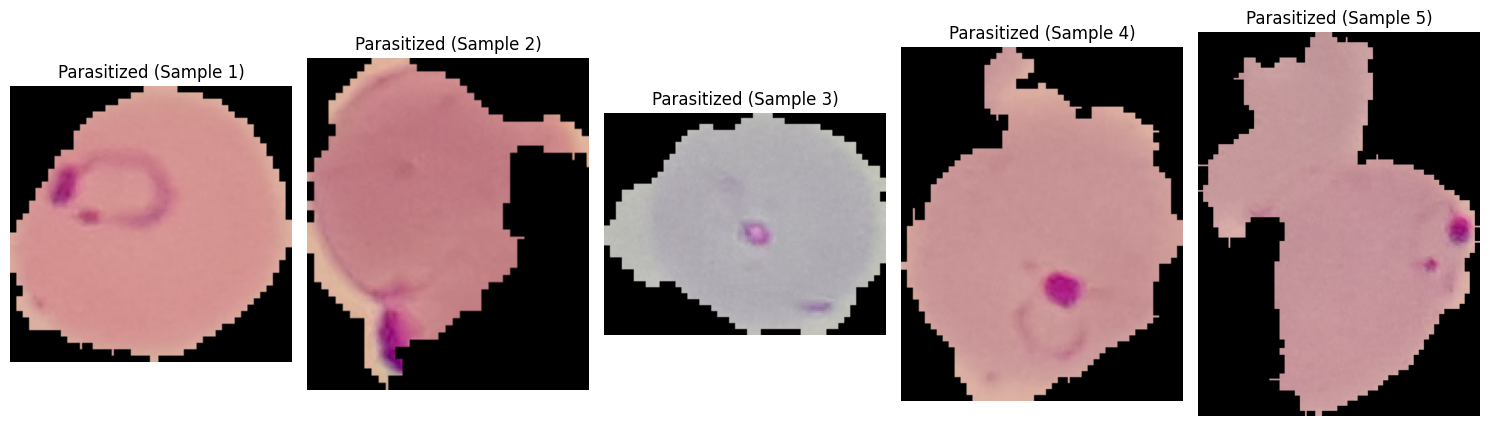

In [ ]:
# specifying the path to the parasitized images
parasitized_path = '/content/malaria_dataset/cell_images/Parasitized'

# getting a list of all image files in the directory
parasitized_image_files = [f for f in os.listdir(parasitized_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

if not parasitized_image_files:
    print(f"No image files found in {parasitized_path}. Please check the path and contents.")
else:
    # selecting up to 5 random images to display
    num_images_to_display = min(5, len(parasitized_image_files))
    selected_images = random.sample(parasitized_image_files, num_images_to_display)

    plt.figure(figsize=(15, 5))
    for i, img_name in enumerate(selected_images):
        img_path = os.path.join(parasitized_path, img_name)
        try:
            img = Image.open(img_path)
            ax = plt.subplot(1, num_images_to_display, i + 1)
            plt.imshow(img)
            plt.title(f"Parasitized (Sample {i+1})")
            plt.axis("off")
        except Exception as e:
            print(f"Could not load image {img_name}: {e}")
    plt.tight_layout()
    plt.show()


## Step 4.2 Viewing the Uninffected Images (Non-Malaria Blood Smear Samples)

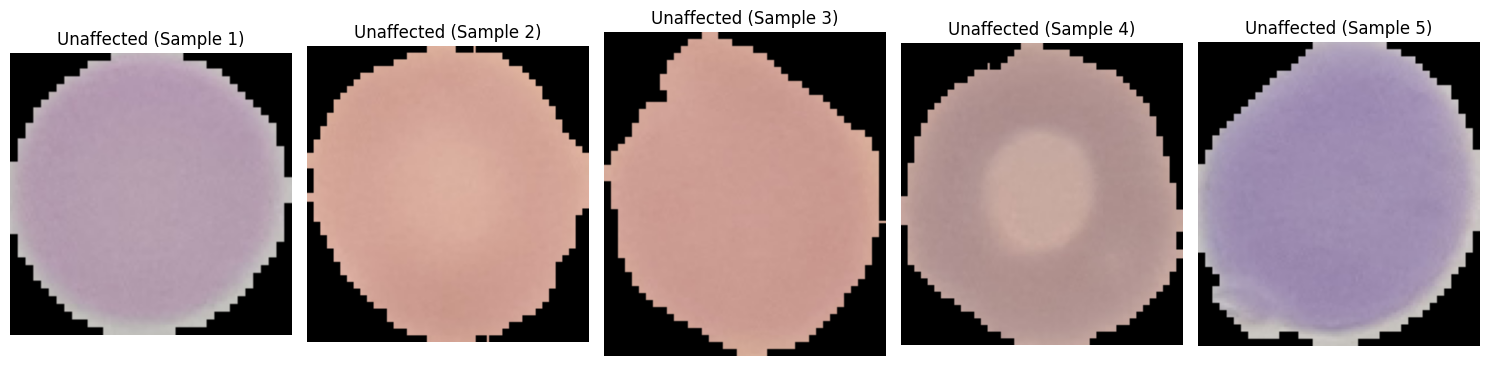

In [ ]:
# specifying the path to the parasitized images
uninffected_path = '/content/malaria_dataset/cell_images/Uninfected'

# getting a list of all image files in the directory
unaffected_image_files = [f for f in os.listdir(uninffected_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

if not unaffected_image_files:
    print(f"No image files found in {uninffected_path}. Please check the path and contents.")
else:
    # selecting up to 5 random images to display
    num_images_to_display = min(5, len(unaffected_image_files))
    selected_images = random.sample(unaffected_image_files, num_images_to_display)

    plt.figure(figsize=(15, 5))
    for i, img_name in enumerate(selected_images):
        img_path = os.path.join(uninffected_path, img_name)
        try:
            img = Image.open(img_path)
            ax = plt.subplot(1, num_images_to_display, i + 1)
            plt.imshow(img)
            plt.title(f"Unaffected (Sample {i+1})")
            plt.axis("off")
        except Exception as e:
            print(f"Could not load image {img_name}: {e}")
    plt.tight_layout()
    plt.show()


# Step 5: Viewing the number of images in both the Parasitized and Unaffected Images

In [ ]:
print('Total number of images for Parasitized cases:', len(parasitized_image_files))

Total number of images for Parasitized cases: 13779


In [ ]:
print('Total number of images for unaffected cases:', len(unaffected_image_files))

Total number of images for unaffected cases: 13779


## Step 5.1: Viewing the file names for the five 10 images in the parasitized and Unaffected data samples

In [ ]:
# for parasitized images
print(parasitized_image_files[:5])

['C189P150ThinF_IMG_20151203_141901_cell_82.png', 'C101P62ThinF_IMG_20150923_170344_cell_82.png', 'C51AP12thinF_IMG_20150724_154243_cell_122.png', 'C97P58ThinF_IMG_20150917_151320_cell_161.png', 'C133P94ThinF_IMG_20151004_154351_cell_111.png']


In [ ]:
# for unaffected images
print(unaffected_image_files[:5])

['C235ThinF_IMG_20151112_164834_cell_112.png', 'C70P31_ThinF_IMG_20150813_130849_cell_69.png', 'C85P46ThinF_IMG_20150820_110040_cell_3.png', 'C157P118ThinF_IMG_20151115_163915_cell_138.png', 'C58P19thinF_IMG_20150802_122846_cell_136.png']


# step 6: Checking if the number if images for Parasitized and Uninfected files are same in number or there is difference

In [ ]:
# Checking for the difference between the number of parasitized and uninfected blood smear images
print('Difference between the number of images with parasitized and uninfected is:', len(parasitized_image_files) - len(unaffected_image_files))

Difference between the number of images with parasitized and uninfected is: 0


# step 8: Creating Labels for the Parasitized and Uninfected images

In [ ]:
 # Creating the labels for parasitized image files to be ones (1's)
parasitized_labels = [1]*len(parasitized_image_files)

In [ ]:
parasitized_labels[:10]

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

In [ ]:
 # Creating the labels for uninfected image files to be ones (0's)
uninfected_labels = [0]*len(unaffected_image_files)
uninfected_labels [:10]

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

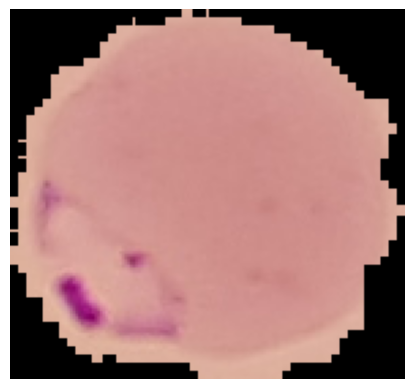

In [ ]:
# displaying individuals parasite images  with face mask
img =mpimg.imread('/content/malaria_dataset/cell_images/Parasitized/C128P89ThinF_IMG_20151004_131231_cell_158.png')
imgplot = plt.imshow(img)
plt.axis('off')
plt.show()

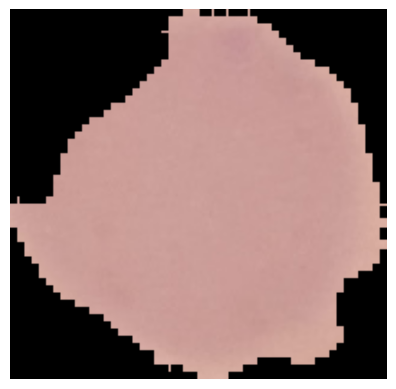

In [ ]:
# displaying individuals parasite images  with face mask
img =mpimg.imread('/content/malaria_dataset/cell_images/Uninfected/C85P46ThinF_IMG_20150820_105301_cell_124.png')
imgplot = plt.imshow(img)
plt.axis('off')
plt.show()

# Step 9: Image Processing

In [ ]:
# resizing and converting all the images to numpy array
para_path = '/content/malaria_dataset/cell_images/Parasitized/'
uninfected_path = '/content/malaria_dataset/cell_images/Uninfected/'
images=[]
labels=[] # Initialize labels list to store corresponding labels

# Process parasitized images
for img_file in parasitized_image_files:
  image=Image.open(os.path.join(para_path, img_file))
  image=image.resize((128,128))
  image=image.convert('RGB')
  image=np.array(image)
  images.append(image)
  labels.append(1) # Label 1 for parasitized

# Process uninfected images
for img_file in  unaffected_image_files:
  image=Image.open(os.path.join(uninfected_path, img_file))
  image=image.resize((128,128))
  image=image.convert('RGB')
  image=np.array(image)
  images.append(image)
  labels.append(0) # Label 0 for uninfected

print(f"Successfully processed {len(images)} images and {len(labels)} labels.")


Successfully processed 27558 images and 27558 labels.


In [ ]:
  # viewing the length of the combined resize images
print(len(images))

27558


In [ ]:
# checking for the size and the color channel in the first resized image
images[0].shape

(128, 128, 3)

In [ ]:
# checking for the size and the color channel in the first resized image
images[-1].shape

(128, 128, 3)

In [ ]:
print(len(labels))

27558


# step 10: Visualizing the Resized images

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
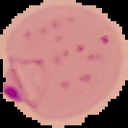

In [ ]:
images[1]
# The parasitized image below  as been resized to have the size of 128 by 128 with three color channels (RGB)

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
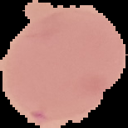

In [ ]:
images[-1]
# The uninfected bloog image below  as been resized to have the size of 128 by 128 with three color channels (RGB)

All the blood smear images containing both parasitized and uninfected sample have been resized to have the same size of 128 width and 128 height. Image Resizing is one of the crucial steps required when training image-based machine learning models, as all images are required to be in the same size and having same color channel for effective model learning.

# step 11: Converting the images and labels to numpy Array

In [ ]:
# conveting the labels and the combined images we created before to a numpy array
x=np.array(images)
y=np.array(labels)

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
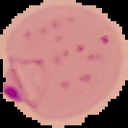

In [ ]:
# let's view the images after converting them into numpy array

x[1]


# step 12: Data Splitting Phase

In [ ]:
# let's split the combine image data into training and test sets

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=2)

# printing the shape of the x-array and the x_train and x_test values
print("The training size is:", x_train.shape)
print("the test size is:",x_test.shape)

The training size is: (22046, 128, 128, 3)
the test size is: (5512, 128, 128, 3)


array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
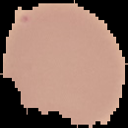

In [ ]:
# visulizing the first three images in the training data
x_train[5]

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
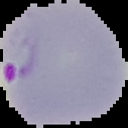

In [ ]:
x_train[2000]

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
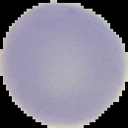

In [ ]:
x_train[300]

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
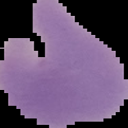

In [ ]:
# let's visualize the images in the test data
x_test[0]

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
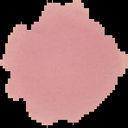

In [ ]:
x_test[5000]

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
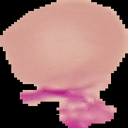

In [ ]:
x_test[300]

# Step 13: Setting Up the Architecture of the CNN Model while Performing Data scaling

In [ ]:
from tensorflow import keras

num_of_classes = 2

model = keras.Sequential()

model.add(keras.layers.Rescaling(1./255, input_shape=(128,128,3)))

model.add(keras.layers.Conv2D(32, kernel_size=(3,3), activation='relu'))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Conv2D(64, kernel_size=(3,3), activation='relu'))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(128, activation='relu'))
model.add(keras.layers.Dropout(0.5))

model.add(keras.layers.Dense(64, activation='relu'))
model.add(keras.layers.Dropout(0.5))

model.add(keras.layers.Dense(1, activation='sigmoid'))


# Step 14: Compiling the Model After the Architecture was built

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


# Step 14.1: Setting Early stopping Technique

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',      # watch validation loss
    patience=3,              # wait 3 epochs before stopping
    restore_best_weights=True
)


# Step 15: MODEL TRAINING

In [ ]:
history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=30,# number of time the CNN model will iterate on the dataset
    batch_size=32, # the CNN model is set to use 32 images at a time before updating model weight
    shuffle=True,
    callbacks=[early_stop] # early stop to prevent model overfitting
)

Epoch 1/30
621/621 ━━━━━━━━━━━━━━━━━━━━ 21s 23ms/step - accuracy: 0.7700 - loss: 0.5073 - val_accuracy: 0.9156 - val_loss: 0.3070
Epoch 2/30
621/621 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9292 - loss: 0.2595 - val_accuracy: 0.9438 - val_loss: 0.1746
Epoch 3/30
621/621 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9436 - loss: 0.1959 - val_accuracy: 0.9424 - val_loss: 0.1909
Epoch 4/30
621/621 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9499 - loss: 0.1673 - val_accuracy: 0.9497 - val_loss: 0.1646
Epoch 5/30
621/621 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9579 - loss: 0.1388 - val_accuracy: 0.9451 - val_loss: 0.1907
Epoch 6/30
621/621 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9649 - loss: 0.1124 - val_accuracy: 0.9465 - val_loss: 0.1822
Epoch 7/30
621/621 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9682 - loss: 0.0986 - val_accuracy: 0.9456 - val_loss: 0.1938


# Step 16: Visualizing Model Evaluation

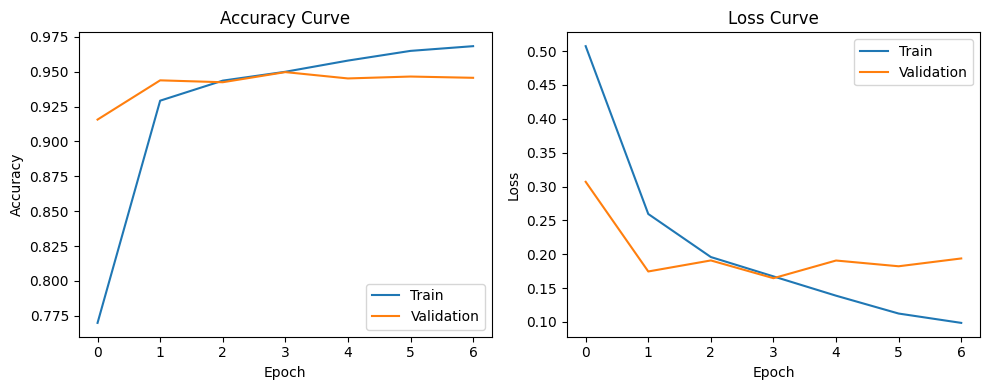

In [ ]:
plt.figure(figsize=(10,4))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.tight_layout()
plt.show()


# step 16.1: Visualizing the Train model Confusion Matrix and AUC scores on training data

Training Precision: 0.9648
Training Recall:    0.9658
Training F1-score:  0.9653
Training AUC:       0.9916


<Figure size 600x500 with 0 Axes>

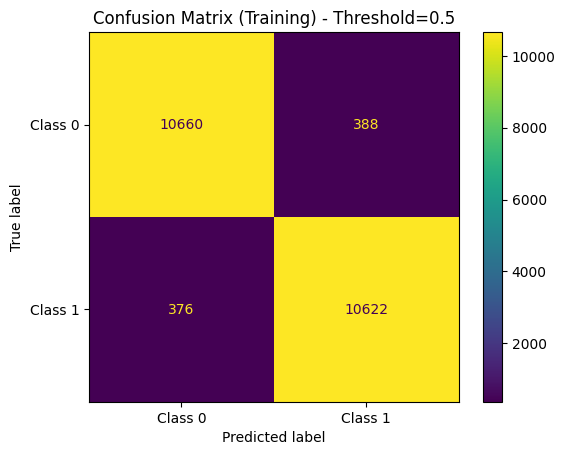

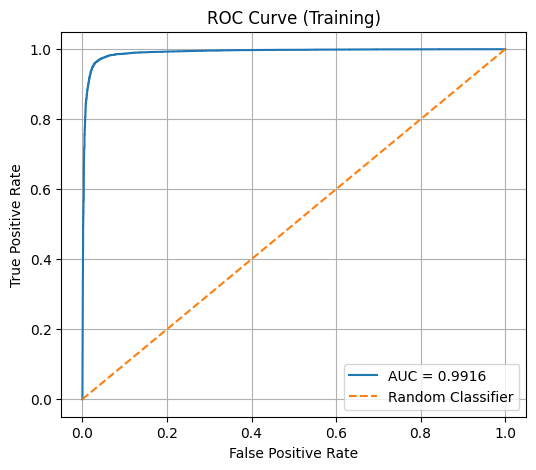

In [ ]:

# getting predicted probabilities and predicted classes on training data
y_train_prob = model.predict(x_train, verbose=0).ravel()  # probabilities (0..1)
threshold = 0.5
y_train_pred = (y_train_prob >= threshold).astype(int)   # class predictions (0/1)

# Ensure y_train is 1D
y_true = np.array(y_train).ravel()

# 2) computing the metrics
precision = precision_score(y_true, y_train_pred)
recall = recall_score(y_true, y_train_pred)
f1 = f1_score(y_true, y_train_pred)
auc = roc_auc_score(y_true, y_train_prob)

print(f"Training Precision: {precision:.4f}")
print(f"Training Recall:    {recall:.4f}")
print(f"Training F1-score:  {f1:.4f}")
print(f"Training AUC:       {auc:.4f}")

# 3) confusion Matrix (visual)
cm = confusion_matrix(y_true, y_train_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1"])

plt.figure(figsize=(6,5))
disp.plot(values_format='d')
plt.title(f"Confusion Matrix (Training) - Threshold={threshold}")
plt.show()

# 4) ROC Curve (AUC visual)
fpr, tpr, _ = roc_curve(y_true, y_train_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve (Training)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


# Step 16.2: Visualizing the trained model  

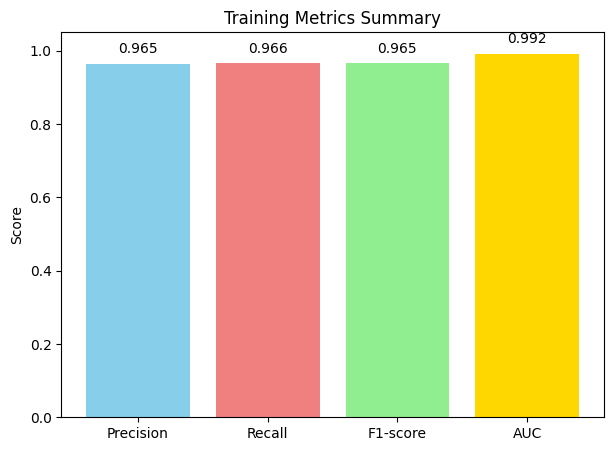

In [ ]:
metrics_names = ["Precision", "Recall", "F1-score", "AUC"]
metrics_values = [precision, recall, f1, auc]

plt.figure(figsize=(7,5))
colors = ['skyblue', 'lightcoral', 'lightgreen', 'gold']
bars = plt.bar(metrics_names, metrics_values, color=colors)

plt.ylim(0, 1.05)
plt.title("Training Metrics Summary")
plt.ylabel("Score")

for bar, val in zip(bars, metrics_values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}",
             ha='center', va='bottom')
plt.show()

# Step 17: Evaluating Model on Test Data

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")


Test Accuracy: 0.9470
Test Loss: 0.1718


As clearly seen from the model score, the model archiv

In [ ]:
y_test_prob = model.predict(x_test, verbose=0).ravel()
threshold = 0.5
y_test_pred = (y_test_prob >= threshold).astype(int)
y_true = np.array(y_test).ravel()

In [ ]:


precision = precision_score(y_true, y_test_pred)
recall = recall_score(y_true, y_test_pred)
f1 = f1_score(y_true, y_test_pred)
auc = roc_auc_score(y_true, y_test_prob)

print(f"Test Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")
print(f"Test AUC:       {auc:.4f}")


Test Precision: 0.9498
Test Recall:    0.9450
Test F1-score:  0.9474
Test AUC:       0.9805


<Figure size 600x500 with 0 Axes>

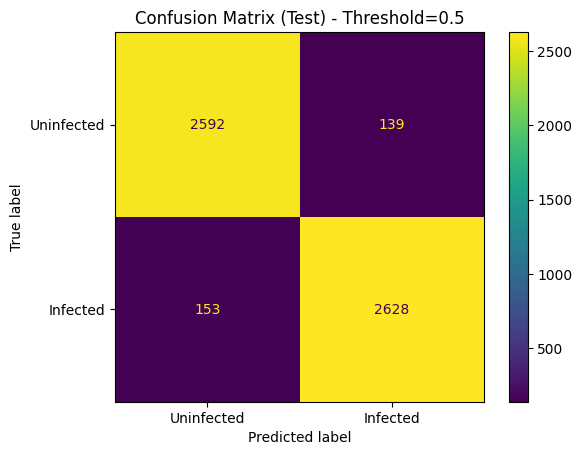

In [ ]:

cm = confusion_matrix(y_true, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Uninfected", "Infected"])

plt.figure(figsize=(6,5))
disp.plot(values_format='d')
plt.title(f"Confusion Matrix (Test) - Threshold={threshold}")
plt.show()


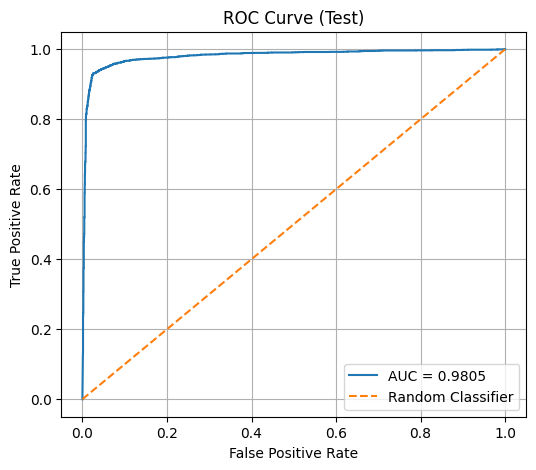

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_true, y_test_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve (Test)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


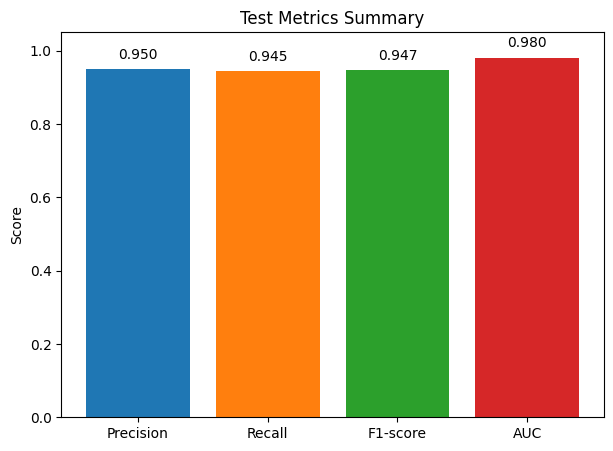

In [ ]:
metrics_names = ["Precision", "Recall", "F1-score", "AUC"]
metrics_values = [precision, recall, f1, auc]

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # different colors

plt.figure(figsize=(7,5))
bars = plt.bar(metrics_names, metrics_values, color=colors)

plt.ylim(0, 1.05)
plt.title("Test Metrics Summary")
plt.ylabel("Score")

for bar, val in zip(bars, metrics_values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}",
             ha='center', va='bottom')

plt.show()


# SAVING THE MODEL AS FOR DEPLOYMENT

In [ ]:
model.save("malaria_cnn_model.keras")


# BUILDING PREDICTIVE SYSTEM AND USING THE MODEL FOR MALARIA PARASITE DETECTION

In [ ]:
# loading the saved model
MODEL_PATH = "/content/malaria_cnn_model.keras"
model = load_model(MODEL_PATH)
print(" Model loaded successfully!")

 Model loaded successfully!


In [ ]:
CLASS_NAMES = ["Uninfected", "Infected"]
IMG_SIZE = (128, 128)
THRESHOLD = 0.5

In [ ]:
upload_widget = widgets.FileUpload(
    accept='image/',
    multiple=False,
    description="Upload Image"
)

predict_button = widgets.Button(
    description="Predict",
    button_style='success'
)

output = widgets.Output()

def preprocess_image(image_bytes):
    # loading image
    img = Image.open(io.BytesIO(image_bytes)).convert("RGB")
    # Resizing to model input
    img_resized = img.resize(IMG_SIZE)
    # converting to array (keep 0..255; Rescaling is inside your model)
    img_array = np.array(img_resized, dtype=np.uint8)
    # adding batch dimension
    img_batch = np.expand_dims(img_array, axis=0)
    return img, img_resized, img_batch

def on_predict_clicked(b):
    with output:
        clear_output()

        if len(upload_widget.value) == 0:
            print("Please upload an image first.")
            return

        # Get uploaded file bytes
        file_info = list(upload_widget.value.values())[0]
        image_bytes = file_info["content"]

        # Preprocess
        original_img, resized_img, img_batch = preprocess_image(image_bytes)

        # Display image
        plt.figure(figsize=(4,4))
        plt.imshow(original_img)
        plt.axis("off")
        plt.title("Uploaded Image")
        plt.show()

        # Predict
        prob = model.predict(img_batch, verbose=0).ravel()[0]  # sigmoid output
        pred_class = int(prob >= THRESHOLD)

        print("Prediction Result")
        print(f"Probability (Infected): {prob:.3f}")
        print(f"Predicted Class: {CLASS_NAMES[pred_class]}")
        print(f"Decision Threshold: {THRESHOLD}")

predict_button.on_click(on_predict_clicked)

display(widgets.HBox([upload_widget, predict_button]))
display(output)

Output()

In [ ]:
from IPython.display import FileLink, display

# Get the first five parasitized image filenames
first_five_parasitized = parasitized_image_files[:5]

print("Downloading the first five parasitized images:")
for img_name in first_five_parasitized:
    file_path = os.path.join(parasitized_path, img_name)
    print(f"Click to download {img_name}:")
    display(FileLink(file_path))


Click to download C189P150ThinF_IMG_20151203_141901_cell_82.png:


/content/malaria_dataset/cell_images/Parasitized/C189P150ThinF_IMG_20151203_141901_cell_82.png

Click to download C101P62ThinF_IMG_20150923_170344_cell_82.png:


/content/malaria_dataset/cell_images/Parasitized/C101P62ThinF_IMG_20150923_170344_cell_82.png

Click to download C51AP12thinF_IMG_20150724_154243_cell_122.png:


/content/malaria_dataset/cell_images/Parasitized/C51AP12thinF_IMG_20150724_154243_cell_122.png

Click to download C97P58ThinF_IMG_20150917_151320_cell_161.png:


/content/malaria_dataset/cell_images/Parasitized/C97P58ThinF_IMG_20150917_151320_cell_161.png

Click to download C133P94ThinF_IMG_20151004_154351_cell_111.png:


/content/malaria_dataset/cell_images/Parasitized/C133P94ThinF_IMG_20151004_154351_cell_111.png